In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error)


In [72]:
FILE = "/workspaces/data-science-and-machine-learning-courses/data/AESO 2023-2026 Data.csv"


In [64]:
print("Loading data...")

pd.read_csv(FILE, sep=",")

print(f"Rows loaded: {len(df):,}")

Loading data...
Rows loaded: 30,644


In [73]:
df.head(20)

,Date (MST),Date (MPT),Weekday,Day,Month,Year,Hour,Wood/Refuse,WIND,SIMPLE_CYCLE,...,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46
0,2023-01-01 00:00:00,2023-01-01 00:00:00,Sunday,1.0,1.0,2023.0,0.0,93.895204,780.206753,462.283983,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-01 01:00:00,2023-01-01 01:00:00,Sunday,1.0,1.0,2023.0,1.0,92.715057,732.207446,464.323759,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-01 02:00:00,2023-01-01 02:00:00,Sunday,1.0,1.0,2023.0,2.0,92.811904,743.884060,466.660278,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-01 03:00:00,2023-01-01 03:00:00,Sunday,1.0,1.0,2023.0,3.0,93.257066,759.293766,461.777699,...,Biomass/Other,Gas Fired Steam,Gas Combined Cycle,Biomass/Other,Biomass/Other,Storage,Coal,Hybrid,Biomass/Other,Biomass/Other
4,2023-01-01 04:00:00,2023-01-01 04:00:00,Sunday,1.0,1.0,2023.0,4.0,92.917893,746.124896,461.075801,...,Gas,GAS_FIRED_STEAM,COMBINED_CYCLE,Gas cogen,Biomass,ENERGY STORAGE,COAL,DUAL FUEL,Oil/Gas,Composite
5,2023-01-01 05:00:00,2023-01-01 05:00:00,Sunday,1.0,1.0,2023.0,5.0,94.105890,705.325952,458.911326,...,0,0.5575,0.3058,0.2581,0.0439,0,1.036,0.79675,0,0.0439
6,2023-01-01 06:00:00,2023-01-01 06:00:00,Sunday,1.0,1.0,2023.0,6.0,96.520140,671.717422,448.598104,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2023-01-01 07:00:00,2023-01-01 07:00:00,Sunday,1.0,1.0,2023.0,7.0,95.086348,623.582679,534.119067,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2023-01-01 08:00:00,2023-01-01 08:00:00,Sunday,1.0,1.0,2023.0,8.0,96.406156,574.672781,555.045837,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2023-01-01 09:00:00,2023-01-01 09:00:00,Sunday,1.0,1.0,2023.0,9.0,95.366069,481.770338,551.854838,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
# Split the data into training (70%) and test sets (30%)

from sklearn.model_selection import train_test_split

X = df.loc[:, "Year":"Oil/Gas"]
y = df.loc[:, "Demand (MW)"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(
    f"X_train shape: {X_train.shape}, percentage of training data: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(
    f"X_test shape: {X_test.shape}, percentage of test data: {X_test.shape[0] / X.shape[0]:.2%}"
)

KeyError: 'Demand (MW)'

In [57]:
from sklearn.neural_network import MLPRegressor

# Fit an artificial neural network (ANN) model to the standardized training data
ann = MLPRegressor(
    hidden_layer_sizes=(50,),
    activation="relu",
    solver="adam",
    learning_rate="constant",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,  # set random seed for reproducibility, we get same results each time
).fit(X_train, y_train)

# Make predictions on the standardized test data
y_pred = ann.predict(X_test)
print(f"Predictions on the test set: {y_pred}\n")

# Training and test set scores
print("----------- ANN Model Scores -----------")
print(f"Training set score: {ann.score(X_train, y_train):.4f}")
print(f"Test set score: {ann.score(X_test, y_test):.4f}")

Predictions on the test set: [10603.61695189  9269.67613474  8946.8724378  ... 10861.00613543
 10274.78865212 10561.18152853]

----------- ANN Model Scores -----------
Training set score: 0.8744
Test set score: 0.8760


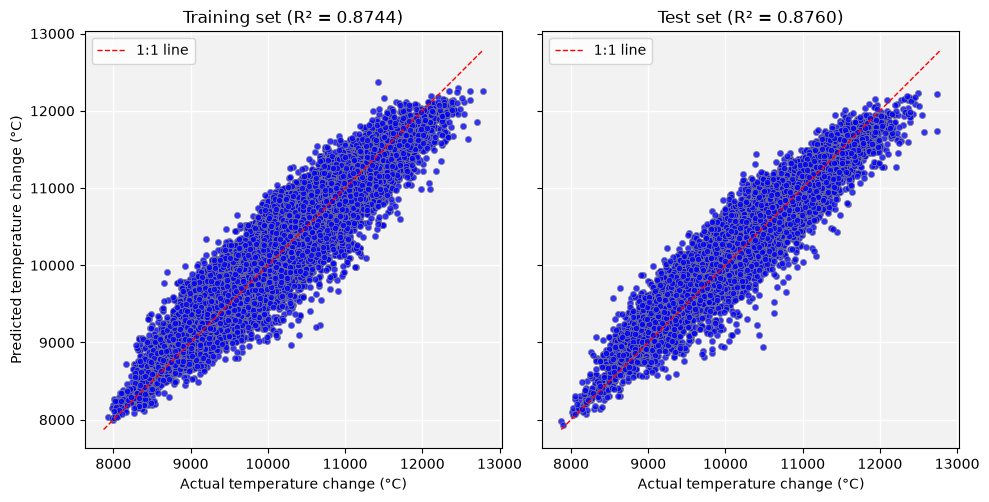

In [58]:
# Crossplots of actual vs. predicted values for the training and test sets
y_train_pred = ann.predict(X_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
for ax, X_set, y_true, y_hat, name in zip(
    axes,
    [X_train, X_test],
    [y_train, y_test],
    [y_train_pred, y_pred],
    ["Training", "Test"],
):
    ax.scatter(
        y_true,
        y_hat,
        c="blue",
        s=20,
        edgecolor="grey",
        linewidth=0.6,
        alpha=0.8,
    )
    ax.set_title(f"{name} set (R² = {ann.score(X_set, y_true):.4f})")
    ax.set_xlabel("Actual temperature change (°C)")

# 1:1 line: points on this line are perfect predictions
lims = [
    min(y.min(), y_train_pred.min(), y_pred.min()),
    max(y.max(), y_train_pred.max(), y_pred.max()),
]
for ax in axes:
    ax.plot(lims, lims, color="red", linestyle="--", linewidth=1, label="1:1 line")
    ax.set_aspect("equal")
    ax.legend()
axes[0].set_ylabel("Predicted temperature change (°C)")

fig.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white", linewidth=1)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()